# 👁️ Real-Time Blind Assistance System (Webcam + YOLO + Voice)

**Pipeline:** laptop webcam → YOLO obstacle detection → direction (left / ahead / right) → distance estimate → spoken warning

| Part | What it does |
|---|---|
| 1. Setup | GPU check, install libraries |
| 2. Config | All settings in one place (mode, thresholds, voice) |
| 3. Models | Pretrained YOLO (+ optional custom model for stairs / doors / potholes) |
| 4. Obstacle logic | Filtering, direction, distance, priority, alert cooldown |
| 5. Test on image | Quick check before going live |
| 6. **Live webcam** | Continuous real-time loop with voice alerts |
| 7. (Optional) Train custom model | Fine-tune on obstacles COCO does not contain |
| 8. Evaluation | mAP, latency, FPS for your report |

**How to run:** `Runtime → Change runtime type → T4 GPU`, then run cells top to bottom. Use **Chrome** and click *Allow* for camera / microphone.

## 1. Setup

In [ ]:
!pip install -q ultralytics roboflow
import torch
print("PyTorch:", torch.__version__)
print("GPU    :", torch.cuda.get_device_name(0) if torch.cuda.is_available()
      else "NOT FOUND -> Runtime > Change runtime type > T4 GPU")

PyTorch: 2.14.1+cu130
GPU    : Tesla T4


## 2. Configuration (change settings here only)

In [ ]:
MODE = "both"            # "indoor", "outdoor" or "both"  (also changeable by voice while running)
CONF = 0.40              # detection confidence threshold
IMG_SIZE = 640           # YOLO input size (use 480 or 320 for more FPS)

# Distance estimation (approximate - uses object height + camera field of view)
HFOV_DEG = 65            # typical laptop webcam horizontal field of view
VERY_CLOSE_M = 1.0       # below this -> "Stop!" warning if ahead
CLOSE_M = 2.0
ALERT_DISTANCE_M = 3.0   # objects farther than this are ignored

# Voice
COOLDOWN_SEC = 4.0       # do not repeat the same alert more often than this
MAX_ALERTS_PER_FRAME = 2 # speak at most this many objects at once
ENABLE_VOICE_COMMANDS = False   # True = say "indoor", "outdoor", "describe", "mute", "unmute"

# Webcam
FLIP_LEFT_RIGHT = False  # True if you demo by facing the laptop (mirror view)

# Models
BASE_MODEL = "yolo26n.pt"   # falls back to yolo11n.pt if unavailable
CUSTOM_MODEL = None         # after training (Part 7) e.g. "/content/drive/MyDrive/blind_assist/best.pt"

## 3. Load models
`base_model` knows 80 everyday COCO classes (person, chair, car, bicycle...).
An optional **custom model** (Part 7) adds classes COCO lacks (stairs, door, pothole, pole...). Both run together, so the base model's knowledge is never lost.

In [ ]:
import os
from ultralytics import YOLO

def load_models():
    try:
        base = YOLO(BASE_MODEL)
    except Exception as e:
        print(f"Could not load {BASE_MODEL} ({e}); falling back to yolo11n.pt")
        base = YOLO("yolo11n.pt")
    loaded = [base]
    if CUSTOM_MODEL and os.path.exists(CUSTOM_MODEL):
        loaded.append(YOLO(CUSTOM_MODEL))
        print("Custom model loaded:", CUSTOM_MODEL)
    return loaded

models = load_models()
for m in models:
    print(len(m.names), "classes:", list(m.names.values())[:12], "...")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
80 classes: ['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'stop sign'] ...


## 4. Obstacle logic
This is the brain of the project: which detections matter, **where** they are, **how far**, and **what to say**.

In [ ]:
import time, math, json, io
from base64 import b64decode, b64encode
import numpy as np
import cv2
from PIL import Image

# ---------- 1. Which classes are relevant obstacles ----------
INDOOR_CLASSES = {
    "person", "chair", "couch", "bed", "dining table", "toilet", "tv", "refrigerator",
    "potted plant", "suitcase", "backpack", "dog", "cat", "oven", "microwave", "sink",
    # custom-model classes (Part 7)
    "stairs", "door", "open door", "closed door", "wall", "table", "glass door",
}
OUTDOOR_CLASSES = {
    "person", "bicycle", "car", "motorcycle", "bus", "truck", "train", "traffic light",
    "stop sign", "fire hydrant", "parking meter", "bench", "dog", "cat", "horse", "cow",
    "potted plant",
    # custom-model classes (Part 7)
    "stairs", "pole", "pothole", "curb", "open manhole", "tree", "barrier",
}
def relevant_classes(mode):
    if mode == "indoor":  return INDOOR_CLASSES
    if mode == "outdoor": return OUTDOOR_CLASSES
    return INDOOR_CLASSES | OUTDOOR_CLASSES

SPEECH_NAME = {"dining table": "table", "potted plant": "plant", "tv": "television",
               "couch": "sofa", "refrigerator": "fridge", "motorcycle": "motorbike"}

# Typical real-world heights (metres) used for the distance estimate
KNOWN_HEIGHT_M = {
    "person": 1.7, "chair": 0.9, "couch": 0.85, "bed": 0.55, "dining table": 0.75,
    "toilet": 0.4, "tv": 0.5, "refrigerator": 1.7, "potted plant": 0.6, "suitcase": 0.6,
    "backpack": 0.45, "dog": 0.5, "cat": 0.3, "oven": 0.6, "microwave": 0.3, "sink": 0.3,
    "bicycle": 1.0, "car": 1.5, "motorcycle": 1.2, "bus": 3.0, "truck": 3.0, "train": 3.5,
    "bench": 0.85, "traffic light": 0.9, "stop sign": 0.75, "fire hydrant": 0.7,
    "parking meter": 1.2, "horse": 1.6, "cow": 1.4, "door": 2.0, "open door": 2.0,
    "closed door": 2.0, "glass door": 2.0, "table": 0.75,
}
SEVERITY = {"very close": 3, "close": 2, "near": 1}
COLORS = {"very close": (255, 40, 40, 255), "close": (255, 150, 0, 255), "near": (40, 200, 80, 255)}

def norm(name):
    return name.lower().replace("_", " ").strip()

# ---------- 2. Direction ----------
def zone_of(cx, width):
    r = cx / width
    if r < 1/3:  return "left"
    if r < 2/3:  return "ahead"
    return "right"

# ---------- 3. Distance (monocular estimate, approximate!) ----------
def focal_px(width):
    return (width / 2) / math.tan(math.radians(HFOV_DEG / 2))

def estimate_distance(name, box, fw, fh):
    x1, y1, x2, y2 = box
    box_h = max(y2 - y1, 1.0)
    area = ((x2 - x1) * (y2 - y1)) / (fw * fh)
    dist = None
    H = KNOWN_HEIGHT_M.get(name)
    if H:
        dist = H * focal_px(fw) / box_h
    # A huge box, or one cut off by the bottom edge, means the object is right in front of us
    if area > 0.35 or (y2 >= fh - 3 and area > 0.20):
        dist = min(dist, VERY_CLOSE_M * 0.9) if dist else VERY_CLOSE_M * 0.9
    return dist, area

def distance_label(dist, area):
    if dist is not None:
        if dist < VERY_CLOSE_M:       return "very close"
        if dist < CLOSE_M:            return "close"
        if dist <= ALERT_DISTANCE_M:  return "near"
        return None                   # too far to matter
    # unknown real size (stairs, pole, pothole...) -> use how much of the frame it fills
    if area > 0.25: return "very close"
    if area > 0.10: return "close"
    if area > 0.04: return "near"
    return None

# ---------- 4. What to say ----------
def make_speech(name, zone, label, dist):
    spoken = SPEECH_NAME.get(name, name)
    where = {"ahead": "ahead", "left": "on your left", "right": "on your right"}[zone]
    if label == "very close" and zone == "ahead":
        return f"Stop! {spoken} very close ahead"
    if dist is not None:
        m = max(round(dist * 2) / 2, 0.5)
        unit = "meter" if m == 1 else "meters"
        return f"{spoken} {where}, about {m:g} {unit}"
    return f"{spoken} {label} {where}"

# ---------- 5. Detect + analyse one frame ----------
def analyze(frame_bgr):
    h, w = frame_bgr.shape[:2]
    allowed = relevant_classes(MODE)
    objs = []
    for m in models:
        res = m.predict(frame_bgr, conf=CONF, imgsz=IMG_SIZE, verbose=False)[0]
        if res.boxes is None:
            continue
        for b in res.boxes:
            name = norm(m.names[int(b.cls[0])])
            if name not in allowed:
                continue
            x1, y1, x2, y2 = [float(v) for v in b.xyxy[0].tolist()]
            dist, area = estimate_distance(name, (x1, y1, x2, y2), w, h)
            label = distance_label(dist, area)
            if label is None:
                continue
            zone = zone_of((x1 + x2) / 2, w)
            objs.append(dict(name=name, conf=float(b.conf[0]), box=(x1, y1, x2, y2), zone=zone,
                             dist=dist, label=label, speech=make_speech(name, zone, label, dist)))
    # most dangerous first: closest, then in our walking path, then nearest by metres
    objs.sort(key=lambda o: (-SEVERITY[o["label"]], o["zone"] != "ahead",
                             o["dist"] if o["dist"] is not None else 99))
    return objs

# ---------- 6. Avoid voice spam: cooldown per (object, zone, distance-level) ----------
class AlertManager:
    def __init__(self):
        self.last = {}
        self.had_obstacles = False
        self.last_clear = 0.0
        self.spoken_count = 0

    def pick(self, objs):
        now = time.time()
        texts = []
        for o in objs:
            key = (o["name"], o["zone"], o["label"])     # level change => new alert immediately
            urgent = o["speech"].startswith("Stop!")
            cooldown = 2.0 if urgent else COOLDOWN_SEC
            if now - self.last.get(key, 0) >= cooldown:
                texts.append(o["speech"])
                self.last[key] = now
            if len(texts) >= MAX_ALERTS_PER_FRAME:
                break
        if not objs and self.had_obstacles and now - self.last_clear > 6:
            texts.append("Path clear")
            self.last_clear = now
        self.had_obstacles = bool(objs)
        if not texts:
            return None
        self.spoken_count += len(texts)
        return {"text": ". ".join(texts), "urgent": any(t.startswith("Stop!") for t in texts)}

# ---------- 7. Drawing ----------
def draw_overlay(objs, shape):
    h, w = shape[:2]
    ov = np.zeros((h, w, 4), np.uint8)
    for x in (w // 3, 2 * w // 3):                       # left | ahead | right guide lines
        cv2.line(ov, (x, 0), (x, h), (255, 255, 255, 90), 1)
    for o in objs:
        x1, y1, x2, y2 = [int(v) for v in o["box"]]
        col = COLORS[o["label"]]
        cv2.rectangle(ov, (x1, y1), (x2, y2), col, 3)
        txt = f"{o['name']} {o['dist']:.1f}m" if o["dist"] is not None else f"{o['name']} {o['label']}"
        (tw, th), _ = cv2.getTextSize(txt, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 2)
        ty = max(y1, th + 8)
        cv2.rectangle(ov, (x1, ty - th - 8), (x1 + tw + 6, ty), col, -1)
        cv2.putText(ov, txt, (x1 + 3, ty - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255, 255), 2)
    return ov

def composite(frame_bgr, ov):
    rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB).astype(np.float32)
    a = ov[:, :, 3:4].astype(np.float32) / 255
    return (rgb * (1 - a) + ov[:, :, :3].astype(np.float32) * a).astype(np.uint8)

def overlay_to_url(ov):
    buf = io.BytesIO()
    Image.fromarray(ov).save(buf, format="png")
    return "data:image/png;base64," + b64encode(buf.getvalue()).decode()

def js_to_image(data_url):
    arr = np.frombuffer(b64decode(data_url.split(",")[1]), dtype=np.uint8)
    return cv2.imdecode(arr, cv2.IMREAD_COLOR)
print("Obstacle logic ready.")

Obstacle logic ready.


## 5. Test on a single image first (optional but recommended)

Saving images1.jpg to images1.jpg


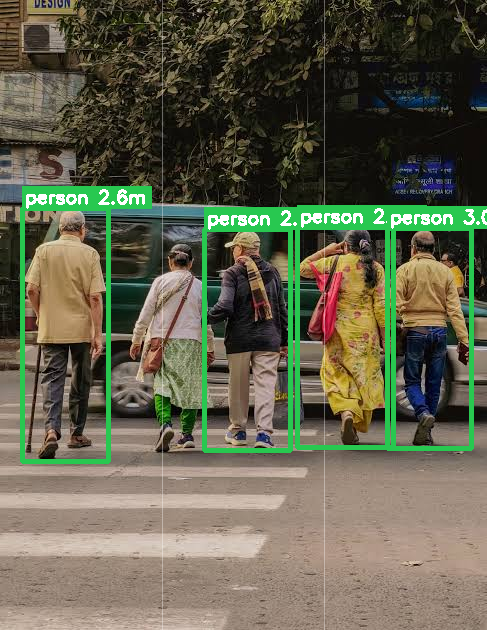

- person ahead, about 3 meters   (confidence 0.83)
- person on your left, about 2.5 meters   (confidence 0.89)
- person on your right, about 3 meters   (confidence 0.86)
- person on your right, about 3 meters   (confidence 0.86)


In [ ]:
from google.colab import files
from IPython.display import display

up = files.upload()
img = cv2.imread(next(iter(up)))
objs = analyze(img)
display(Image.fromarray(composite(img, draw_overlay(objs, img.shape))))
if not objs:
    print("No relevant obstacle within range.")
for o in objs:
    print(f"- {o['speech']}   (confidence {o['conf']:.2f})")

## 6. 🎥 Live webcam with voice alerts
**Step 6a** installs the browser-side code (camera + speech). **Step 6b** runs the real-time loop.

* Click **▶ Start** inside the output (this lets the browser allow the camera and the voice).
* Boxes: 🔴 very close, 🟠 close, 🟢 near. White lines split the view into left / ahead / right.
* Click **⏹ Stop** (or interrupt the cell) to finish — you get FPS / latency stats for your report.
* Real-time speed in Colab depends on your internet (frames travel browser → Colab → browser), typically **~5–15 FPS**. That is fine for a demo.

In [ ]:
from IPython.display import display, Javascript

JS_CODE = """
var video, div = null, stream, captureCanvas, imgElement, labelElement;
var pendingResolve = null, shutdown = false, lastCommand = "", recognition = null;
var W = 640, H = 480;

function removeDom() {
  if (recognition) { try { recognition.onend = null; recognition.stop(); } catch (e) {} recognition = null; }
  if (stream) stream.getTracks().forEach(function (t) { t.stop(); });
  if (div) div.remove();
  div = null; video = null; stream = null;
  window.speechSynthesis.cancel();
}

function onAnimationFrame() {
  if (!shutdown) window.requestAnimationFrame(onAnimationFrame);
  if (pendingResolve) {
    var result = "";
    if (!shutdown) {
      captureCanvas.getContext('2d').drawImage(video, 0, 0, W, H);
      result = captureCanvas.toDataURL('image/jpeg', 0.8);
    }
    var resolve = pendingResolve; pendingResolve = null; resolve(result);
  }
}

function startRecognition() {
  var SR = window.SpeechRecognition || window.webkitSpeechRecognition;
  if (!SR) { console.log('SpeechRecognition not supported'); return; }
  recognition = new SR();
  recognition.continuous = true; recognition.interimResults = false; recognition.lang = 'en-US';
  recognition.onresult = function (e) {
    lastCommand = e.results[e.results.length - 1][0].transcript.toLowerCase().trim();
  };
  recognition.onend = function () { if (recognition && !shutdown) { try { recognition.start(); } catch (err) {} } };
  recognition.onerror = function (e) { console.log('speech recognition error', e.error); };
  try { recognition.start(); } catch (err) {}
}

async function createDom(mirror) {
  div = document.createElement('div');
  div.style.cssText = 'border:2px solid #555;padding:10px;width:' + (W + 20) + 'px;font-family:sans-serif';
  var title = document.createElement('div');
  title.innerHTML = '<b>Blind Assistance - live camera</b>';
  div.appendChild(title);
  labelElement = document.createElement('div');
  labelElement.style.cssText = 'margin:6px 0;font-size:14px';
  div.appendChild(labelElement);

  var startBtn = document.createElement('button');
  startBtn.textContent = '\u25B6 Start';
  startBtn.style.cssText = 'padding:8px 18px;font-size:16px;margin-right:8px';
  var stopBtn = document.createElement('button');
  stopBtn.textContent = '\u23F9 Stop';
  stopBtn.style.cssText = 'padding:8px 18px;font-size:16px';
  stopBtn.onclick = function () { shutdown = true; };
  div.appendChild(startBtn); div.appendChild(stopBtn);

  var holder = document.createElement('div');
  holder.style.cssText = 'position:relative;margin-top:8px;width:' + W + 'px;height:' + H + 'px;background:#000';
  video = document.createElement('video');
  video.muted = true; video.playsInline = true;
  video.style.cssText = 'position:absolute;left:0;top:0;width:' + W + 'px;height:' + H + 'px';
  if (mirror) video.style.transform = 'scaleX(-1)';
  imgElement = document.createElement('img');
  imgElement.style.cssText = 'position:absolute;left:0;top:0;width:' + W + 'px;height:' + H + 'px';
  holder.appendChild(video); holder.appendChild(imgElement); div.appendChild(holder);
  document.body.appendChild(div);

  labelElement.innerHTML = 'Click <b>Start</b> to allow camera and voice...';
  await new Promise(function (resolve) { startBtn.onclick = resolve; });   // user gesture
  startBtn.disabled = true;

  captureCanvas = document.createElement('canvas');
  captureCanvas.width = W; captureCanvas.height = H;
  stream = await navigator.mediaDevices.getUserMedia({video: {width: W, height: H}});
  video.srcObject = stream;
  await video.play();
  window.speechSynthesis.speak(new SpeechSynthesisUtterance('Blind assistance started'));
  window.requestAnimationFrame(onAnimationFrame);
}

async function stream_frame(label, imgData, speech, mirror, voice) {
  if (shutdown) { removeDom(); shutdown = false; return {stopped: true, img: "", cmd: ""}; }
  if (div === null) {
    await createDom(mirror);
    if (voice) startRecognition();
  }
  if (label !== "") labelElement.innerHTML = label;
  if (imgData !== "") imgElement.src = imgData;
  if (speech && speech.text) {
    var synth = window.speechSynthesis;
    if (speech.urgent) synth.cancel();
    if (speech.urgent || !synth.speaking) {
      var u = new SpeechSynthesisUtterance(speech.text);
      u.lang = 'en-US'; u.rate = 1.1;
      synth.speak(u);
    }
  }
  var img = await new Promise(function (resolve) { pendingResolve = resolve; });
  var cmd = lastCommand; lastCommand = "";
  return {stopped: (img === ""), img: img, cmd: cmd};
}
"""
display(Javascript(JS_CODE))
print("Browser-side camera + voice code installed.")

<IPython.core.display.Javascript object>

Browser-side camera + voice code installed.


In [ ]:
from google.colab.output import eval_js

def stop_camera():
    # Closes the camera and cancels speech (only works from the cell that is running the assistant).
    try:
        eval_js('shutdown = true; stream_frame("", "", null, false, false)')
    except Exception:
        pass

def run_assistant(max_seconds=None):
    global MODE
    # JS must be injected in THIS cell's output, otherwise eval_js cannot find stream_frame
    display(Javascript(JS_CODE))
    time.sleep(0.5)
    mgr = AlertManager()
    overlay_url, speech, muted = "", None, False
    label = "Starting..."
    infer_ms_list, frame_times = [], []
    t_start = time.time()
    try:
        while True:
            reply = eval_js('stream_frame({}, {}, {}, {}, {})'.format(
                json.dumps(label), json.dumps(overlay_url), json.dumps(speech),
                json.dumps(FLIP_LEFT_RIGHT), json.dumps(ENABLE_VOICE_COMMANDS)))
            if not reply or reply.get("stopped") or not reply.get("img"):
                break
            frame = js_to_image(reply["img"])
            if FLIP_LEFT_RIGHT:
                frame = cv2.flip(frame, 1)

            # ---- detection ----
            t0 = time.time()
            objs = analyze(frame)
            infer_ms = (time.time() - t0) * 1000
            infer_ms_list.append(infer_ms)

            # ---- voice commands (optional) ----
            cmd = reply.get("cmd", "")
            forced = None
            if cmd:
                if "outdoor" in cmd:     MODE = "outdoor"; forced = "Outdoor mode"
                elif "indoor" in cmd:    MODE = "indoor";  forced = "Indoor mode"
                elif "both" in cmd:      MODE = "both";    forced = "Indoor and outdoor mode"
                elif "unmute" in cmd:    muted = False;    forced = "Voice on"
                elif "mute" in cmd or "quiet" in cmd:
                    muted = True
                elif "describe" in cmd or "what" in cmd:
                    forced = ". ".join(o["speech"] for o in objs[:5]) or "The path looks clear"
                print("Voice command:", cmd)

            if forced:
                speech = {"text": forced, "urgent": True}
            elif muted:
                speech = None
            else:
                speech = mgr.pick(objs)

            overlay_url = overlay_to_url(draw_overlay(objs, frame.shape))

            now = time.time()
            frame_times.append(now)
            fps = (len(frame_times[-10:]) - 1) / (frame_times[-1] - frame_times[-10:][0]) if len(frame_times[-10:]) > 1 else 0
            label = (f"Mode: <b>{MODE}</b> &nbsp;|&nbsp; FPS: <b>{fps:.1f}</b> &nbsp;|&nbsp; "
                     f"Inference: {infer_ms:.0f} ms &nbsp;|&nbsp; Obstacles: {len(objs)}"
                     + (" &nbsp;|&nbsp; \U0001F507 muted" if muted else ""))
            if max_seconds and now - t_start > max_seconds:
                break
    except KeyboardInterrupt:
        print("Interrupted.")
    finally:
        stop_camera()

    total = time.time() - t_start
    if infer_ms_list:
        print(f"Frames processed : {len(infer_ms_list)}")
        print(f"Avg inference    : {np.mean(infer_ms_list):.1f} ms")
        print(f"Avg end-to-end   : {len(infer_ms_list) / total:.1f} FPS (includes browser <-> Colab transfer)")
        print(f"Voice alerts     : {mgr.spoken_count}")

run_assistant()      # <- click Start in the output, then Stop when finished

<IPython.core.display.Javascript object>

Frames processed : 43
Avg inference    : 14.9 ms
Avg end-to-end   : 0.1 FPS (includes browser <-> Colab transfer)
Voice alerts     : 11


## 7. (Optional) Train a custom model for obstacles COCO does not know
COCO has **no** stairs, doors, poles, potholes, curbs or open manholes — and these are the most important obstacles for a blind person.

1. Go to **Roboflow Universe** (universe.roboflow.com), search e.g. *stairs*, *door*, *pothole*, *pole*, *curb*; choose 3–6 classes with a few hundred+ images each (or label your own photos with Roboflow).
2. Copy the *Download → YOLOv8 format → show download code* snippet and paste the workspace / project / version below.
3. Train, then set `CUSTOM_MODEL` in Part 2 to the saved `best.pt` and re-run Part 3.

> ⚠️ Do **not** fine-tune on `coco128` (what the earlier notebook did): the pretrained model already learned COCO, and 5 epochs on 128 images only makes it slightly worse. Train on **new** obstacle classes instead.

In [1]:
!pip install -q roboflow ultralytics


In [2]:
from roboflow import Roboflow

rf = Roboflow(api_key="ZCzZXrBVnroSZ3yjo0WI")

project = rf.workspace("a237s-workspace").project(
    "blind-assistance-starter-dataset"
)

dataset = project.version(1).download(
    model_format="yolov8",
    location="a237s-workspace/blind-assistance-starter-dataset-3-rfdetr-small-t1",
    overwrite=True
)

print("Dataset downloaded to:", dataset.location)


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to a237s-workspace/blind-assistance-starter-dataset-3-rfdetr-small-t1 in yolov8:: 100%|██████████| 1004/1004 [00:00<00:00, 4274.25it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Dataset downloaded to: /content/a237s-workspace/blind-assistance-starter-dataset-3-rfdetr-small-t1


In [3]:
from roboflow import Roboflow
rf = Roboflow(api_key="ZCzZXrBVnroSZ3yjo0WI")
project = rf.workspace("a237s-workspace").project("blind-assistance-starter-dataset")
dataset = project.version(1).download("yolov8")
DATA_YAML = f"{dataset.location}/data.yaml"
print(DATA_YAML)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Blind-Assistance-Starter-Dataset-1 in yolov8:: 100%|██████████| 1004/1004 [00:00<00:00, 2108.01it/s]

/content/Blind-Assistance-Starter-Dataset-1/data.yaml


In [18]:
!pip install -q roboflow ultralytics
from roboflow import Roboflow
from ultralytics import YOLO
import os, shutil

rf = Roboflow(api_key="ZCzZXrBVnroSZ3yjo0WI")
project = rf.workspace("a237s-workspace").project("blind-assistance-starter-dataset")
dataset = project.version(1).download("yolov8")   # change 1 to your version number

DATA_YAML = os.path.join(dataset.location, "data.yaml")
print("DATA_YAML:", DATA_YAML, "| exists:", os.path.exists(DATA_YAML))

loading Roboflow workspace...
loading Roboflow project...
DATA_YAML: /content/Blind-Assistance-Starter-Dataset-1/data.yaml | exists: True


In [20]:
BASE_MODEL = "yolov8n.pt"
train_model = YOLO(BASE_MODEL)
train_results = train_model.train(
    data=DATA_YAML, epochs=50, imgsz=640, batch=16, patience=15,
    project="/content/runs", name="obstacles",
)

BEST = str(train_model.trainer.best)
print("Best weights:", BEST)

from google.colab import drive
drive.mount("/content/drive")
os.makedirs("/content/drive/MyDrive/blind_assist", exist_ok=True)
shutil.copy(BEST, "/content/drive/MyDrive/blind_assist/best.pt")

Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Blind-Assistance-Starter-Dataset-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=obstacles-3, nbs=64, nms=None, opse

'/content/drive/MyDrive/blind_assist/best.pt'

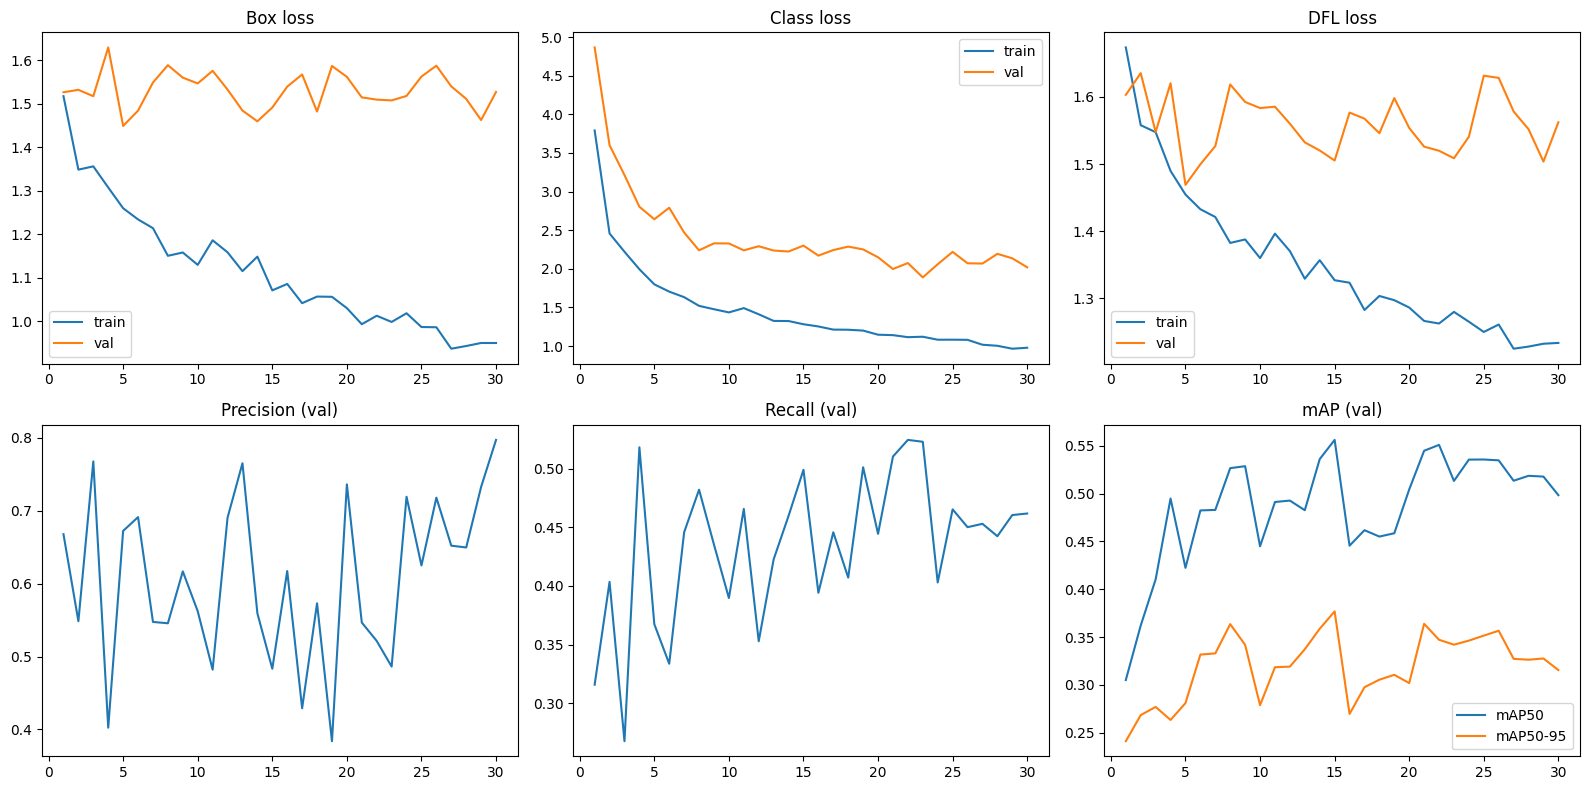

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

results_csv = os.path.join(str(train_model.trainer.save_dir), "results.csv")
df = pd.read_csv(results_csv)
df.columns = df.columns.str.strip()

fig, ax = plt.subplots(2, 3, figsize=(16, 8))
pairs = [
    ("train/box_loss", "val/box_loss", "Box loss"),
    ("train/cls_loss", "val/cls_loss", "Class loss"),
    ("train/dfl_loss", "val/dfl_loss", "DFL loss"),
]
for i, (tr, va, title) in enumerate(pairs):
    ax[0, i].plot(df["epoch"], df[tr], label="train")
    ax[0, i].plot(df["epoch"], df[va], label="val")
    ax[0, i].set_title(title); ax[0, i].legend()

ax[1, 0].plot(df["epoch"], df["metrics/precision(B)"]); ax[1, 0].set_title("Precision (val)")
ax[1, 1].plot(df["epoch"], df["metrics/recall(B)"]);    ax[1, 1].set_title("Recall (val)")
ax[1, 2].plot(df["epoch"], df["metrics/mAP50(B)"], label="mAP50")
ax[1, 2].plot(df["epoch"], df["metrics/mAP50-95(B)"], label="mAP50-95")
ax[1, 2].set_title("mAP (val)"); ax[1, 2].legend()
plt.tight_layout(); plt.show()

In [22]:
best_model = YOLO(str(train_model.trainer.best))

def evaluate(split):
    m = best_model.val(data=DATA_YAML, split=split, imgsz=640, verbose=False,
                       project="/content/runs", name=f"eval_{split}", exist_ok=True)
    return {
        "split": split,
        "precision": round(float(m.box.mp), 4),
        "recall": round(float(m.box.mr), 4),
        "mAP50": round(float(m.box.map50), 4),
        "mAP50-95": round(float(m.box.map), 4),
    }

rows = []
for split in ["train", "val", "test"]:
    try:
        rows.append(evaluate(split))
    except Exception as e:
        print(f"Skipping '{split}': {e}")

summary = pd.DataFrame(rows)
print(summary.to_string(index=False))

Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,138,782 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1423.2±545.1 MB/s, size: 30.1 KB)
val: Scanning /content/Blind-Assistance-Starter-Dataset-1/train/labels.cache... 414 images, 0 backgrounds, 1 corrupt: 100% ━━━━━━━━━━━━ 414/414 108.5Mit/s 0.0s
train: /content/Blind-Assistance-Starter-Dataset-1/train/images/depositphotos_412113618-stock-photo-plastic-orange-cone-pothole-asphalt_jpg.rf.fe7a1f3ce2be7be3fb2ac1c03f2b6a65.jpg: ignoring corrupt image/label: labels mix segment and detection rows
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 520, len(boxes) = 1370. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R    

In [23]:
m = best_model.val(data=DATA_YAML, split="val", imgsz=640, verbose=False)
names = best_model.names
per_class = pd.DataFrame({
    "class": [names[i] for i in m.box.ap_class_index],
    "precision": m.box.p,
    "recall": m.box.r,
    "mAP50": m.box.ap50,
    "mAP50-95": m.box.ap,
}).round(4)
print(per_class.to_string(index=False))

Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,138,782 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1506.0±557.0 MB/s, size: 38.1 KB)
val: Scanning /content/Blind-Assistance-Starter-Dataset-1/valid/labels.cache... 27 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 27/27 7.1Mit/s 0.0s
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 31, len(boxes) = 82. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.1it/s 1.0s
                   all         27         82      0.482      0.499      0.557      0.377
Speed: 3.7ms preprocess, 6.2ms inference, 0.0ms loss, 3.0ms postprocess per image
Results saved to /content/runs/

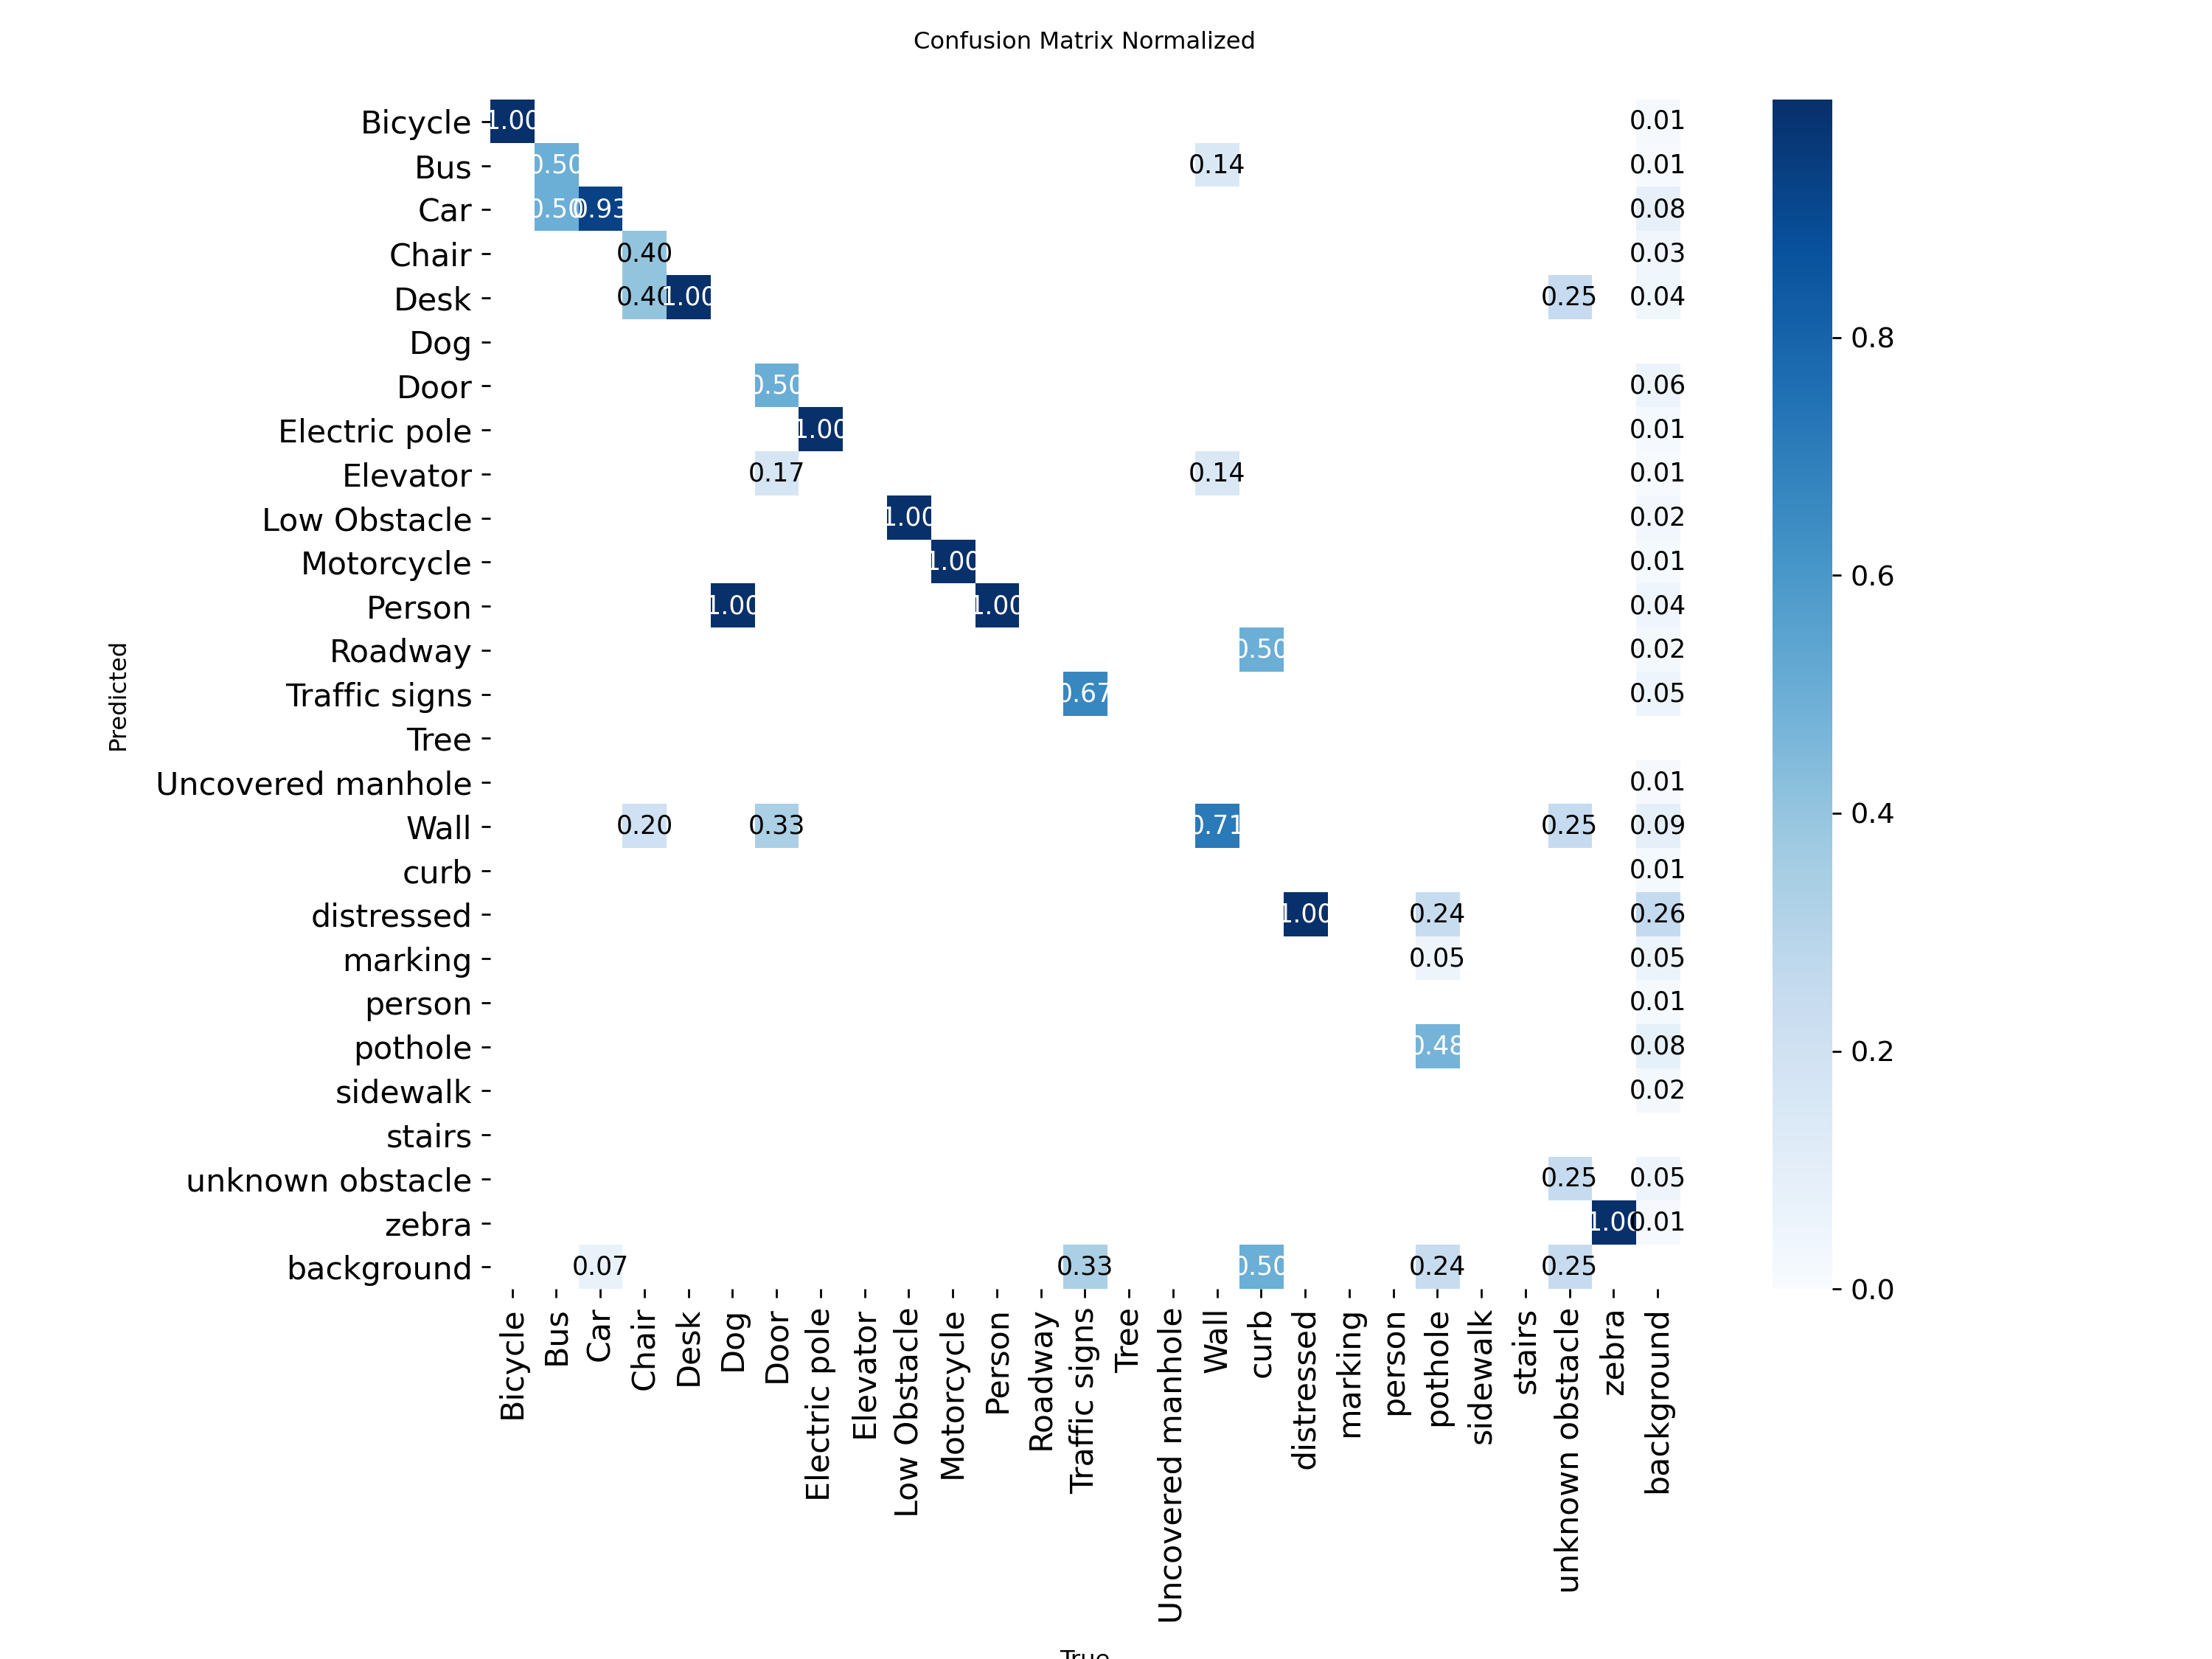

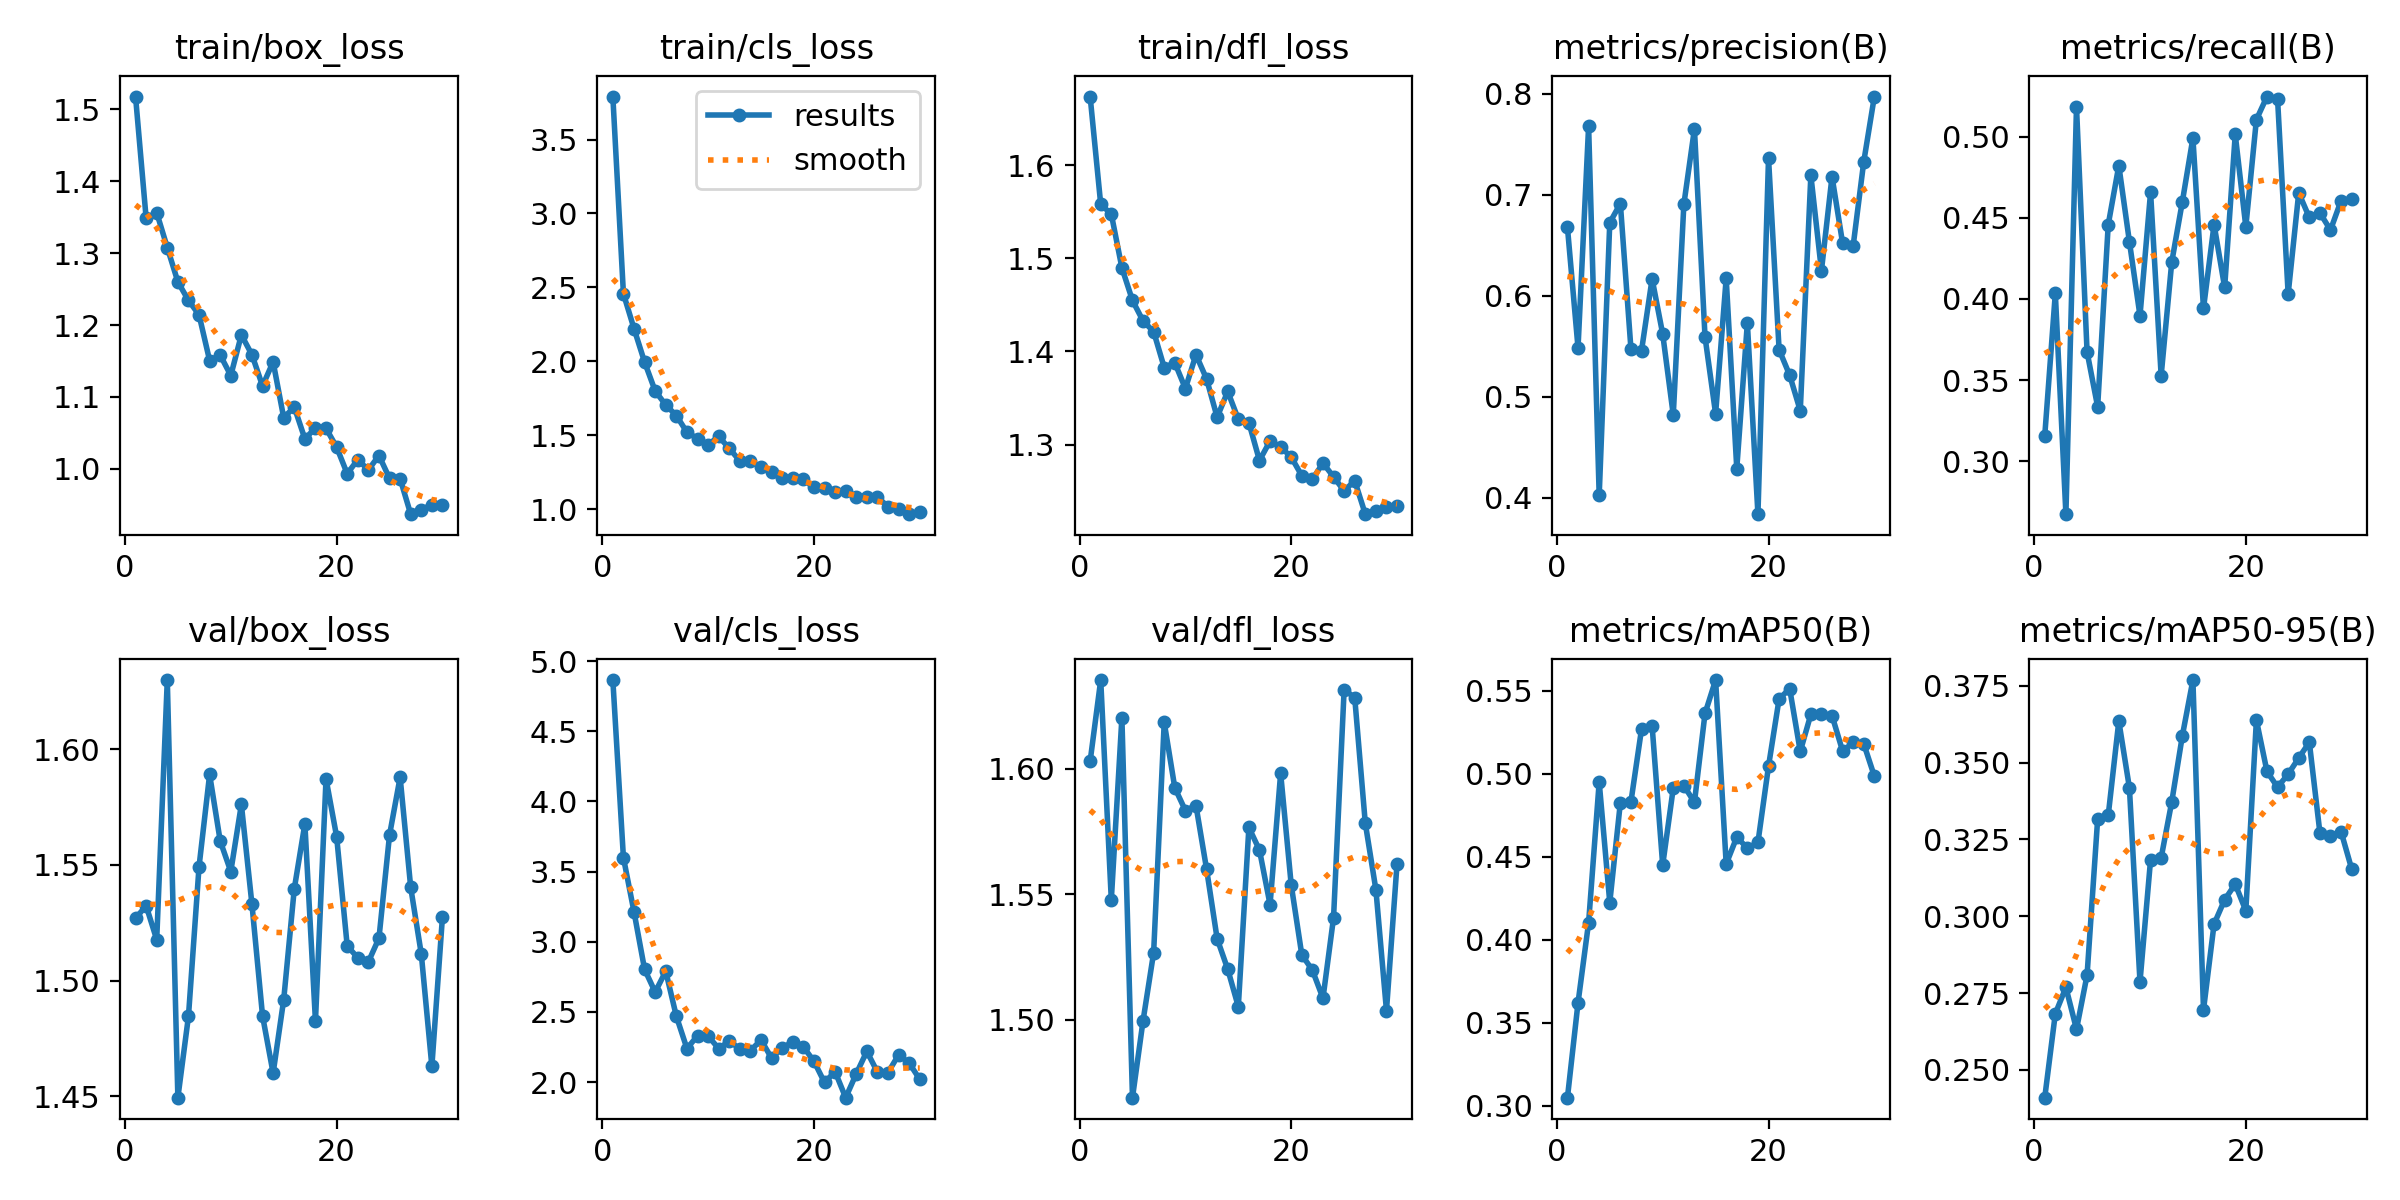

In [24]:
from IPython.display import Image, display
run_dir = str(train_model.trainer.save_dir)
for f in ["confusion_matrix_normalized.png", "PR_curve.png", "results.png"]:
    p = os.path.join(run_dir, f)
    if os.path.exists(p):
        display(Image(filename=p, width=700))

Using 59 images from 'test'

0: 640x640 1 Desk, 1 Door, 1 Low Obstacle, 1 unknown obstacle, 5.2ms
1: 640x640 1 Roadway, 1 sidewalk, 5.2ms
2: 640x640 1 Roadway, 1 sidewalk, 5.2ms
3: 640x640 3 Cars, 1 Tree, 5.2ms
4: 640x640 1 zebra, 5.2ms
5: 640x640 1 Roadway, 1 sidewalk, 5.2ms
6: 640x640 1 Chair, 5.2ms
7: 640x640 2 Roadways, 1 sidewalk, 5.2ms
8: 640x640 (no detections), 5.2ms
9: 640x640 1 Roadway, 1 sidewalk, 5.2ms
10: 640x640 1 zebra, 5.2ms
11: 640x640 2 Roadways, 1 sidewalk, 5.2ms
Speed: 4.1ms preprocess, 5.2ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/realtime_check


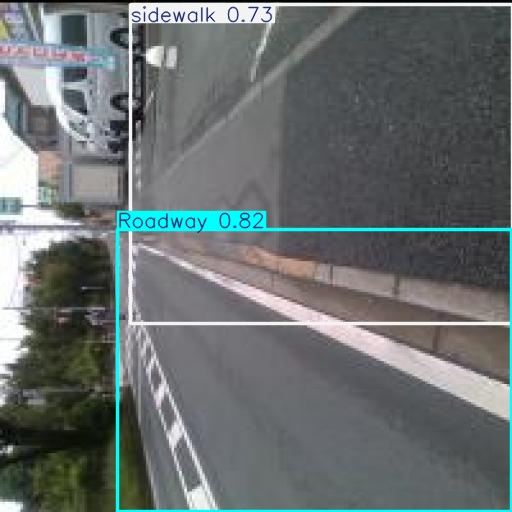

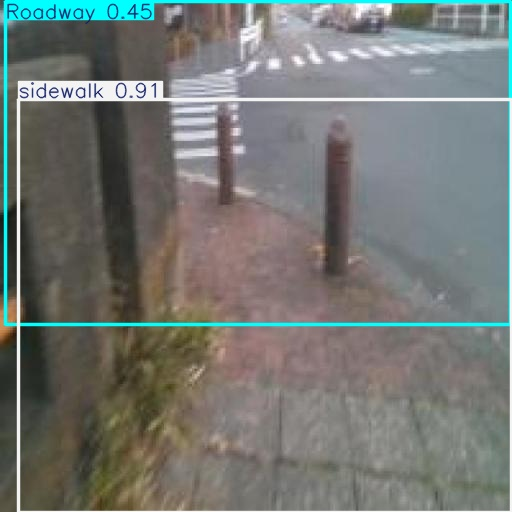

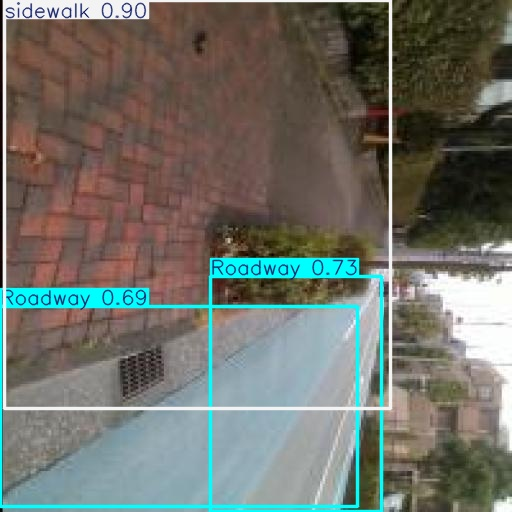

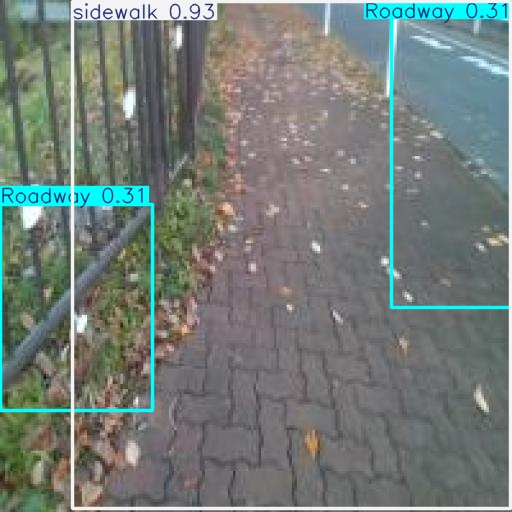

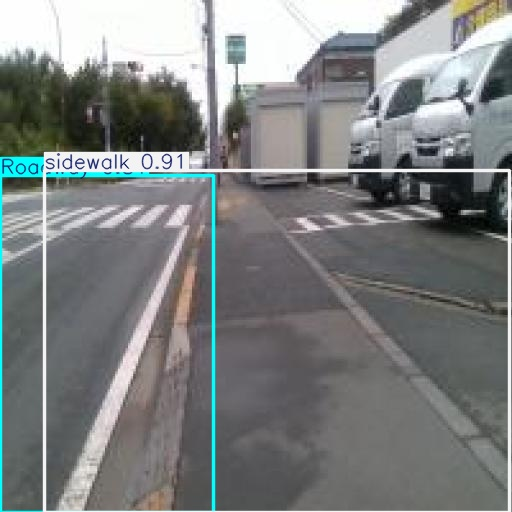

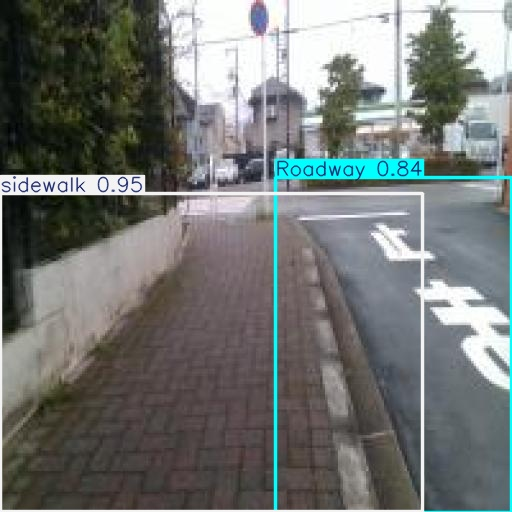

In [26]:
import glob, random
from IPython.display import Image, display

best_model = YOLO(str(train_model.trainer.best))

dataset_root = os.path.dirname(DATA_YAML)
split_dir = "test" if os.path.isdir(os.path.join(dataset_root, "test", "images")) else "valid"
img_paths = glob.glob(os.path.join(dataset_root, split_dir, "images", "*"))
print(f"Using {len(img_paths)} images from '{split_dir}'")

preds = best_model.predict(
    source=random.sample(img_paths, min(12, len(img_paths))),
    conf=0.25, imgsz=640, save=True,
    project="/content/runs", name="realtime_check", exist_ok=True,
)

out_dir = "/content/runs/realtime_check"
for p in sorted(glob.glob(f"{out_dir}/*.jpg"))[:6]:
    display(Image(filename=p, width=500))

In [27]:
import time, numpy as np, cv2

latencies, detections = [], []
for p in img_paths[:100]:
    frame = cv2.imread(p)
    t0 = time.time()
    r = best_model.predict(frame, conf=0.25, imgsz=640, verbose=False)[0]
    latencies.append(time.time() - t0)
    detections.append(len(r.boxes))

lat = np.array(latencies[5:])  # skip warm-up frames
print(f"Frames processed : {len(lat)}")
print(f"Avg latency      : {lat.mean()*1000:.1f} ms")
print(f"Avg FPS          : {1/lat.mean():.1f}")
print(f"Avg detections/frame: {np.mean(detections):.2f}")

Frames processed : 54
Avg latency      : 11.9 ms
Avg FPS          : 84.3
Avg detections/frame: 2.05


In [28]:
# Build a video from dataset images, then run detection on it
sample = img_paths[:60]
h, w = cv2.imread(sample[0]).shape[:2]
writer = cv2.VideoWriter("/content/test_video.mp4",
                         cv2.VideoWriter_fourcc(*"mp4v"), 5, (w, h))
for p in sample:
    writer.write(cv2.resize(cv2.imread(p), (w, h)))
writer.release()

best_model.predict(source="/content/test_video.mp4", conf=0.25, save=True,
                   project="/content/runs", name="video_check", exist_ok=True)
print("Output video saved under /content/runs/video_check/")


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/59) /content/test_video.mp4: 640x640 1 Roadway, 1 sidewalk, 7.7ms
video 1/1 (frame 2/59) /content/test_video.mp4: 640x640 1 Person, 7.6ms
video 1/1 (frame 3/59) /content/test_video.mp4: 640x640 1 sidewalk, 8.3ms
video 1/1 (frame 4/59) /content/test_video.mp4: 640x640 2 Roadways, 1 sidewalk, 7.6ms
video 1/1 (frame 5/59) /content/test_video.mp4: 640x640 1 Motorcycle, 7.6ms
video 1/1 (frame 6/59) /content/test_video.mp4: 640x640 1 Roadway,

<IPython.core.display.Javascript object>


image 1/1 /content/photo.jpg: 480x640 1 Person, 7.0ms
Speed: 1.1ms preprocess, 7.0ms inference, 1.6ms postprocess per image at shape (1, 3, 480, 640)
Results saved to /content/runs/webcam_check


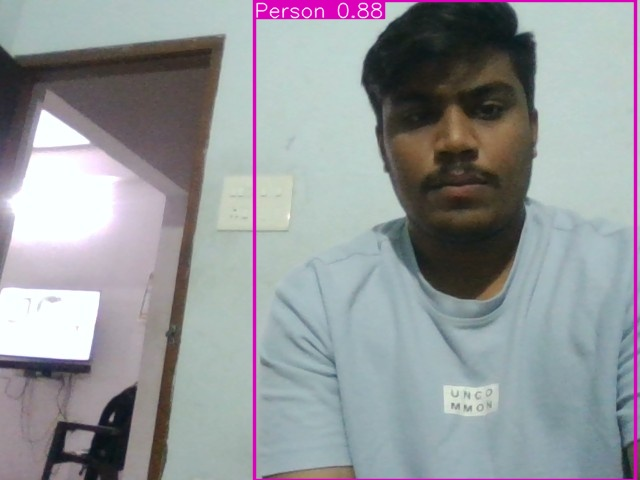

In [37]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

def take_photo(filename="photo.jpg", quality=0.9):
    js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const video = document.createElement('video');
      const btn = document.createElement('button');
      btn.textContent = 'Capture';
      div.appendChild(btn); div.appendChild(video);
      document.body.appendChild(div);
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      video.srcObject = stream; await video.play();
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
      await new Promise(r => btn.onclick = r);
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth; canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop(); div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }''')
    display(js)
    data = eval_js('takePhoto({})'.format(quality))
    with open(filename, 'wb') as f:
        f.write(b64decode(data.split(',')[1]))
    return filename

photo = take_photo()
r = best_model.predict(photo, conf=0.25, save=True,
                       project="/content/runs", name="webcam_check", exist_ok=True)
display(Image(filename=f"/content/runs/webcam_check/{os.path.basename(photo)}", width=600))

## 8. Evaluation numbers for your report

In [39]:
import os, glob, yaml, time
import numpy as np
import pandas as pd
from ultralytics import YOLO

# ---------- 1. Locate weights ----------
candidates = [
    "/content/runs/obstacles/weights/best.pt",
    "/content/runs/detect/obstacles/weights/best.pt",
    "/content/drive/MyDrive/blind_assist/best.pt",
]
try:
    candidates.insert(0, str(train_model.trainer.best))
except NameError:
    pass
BEST = next((p for p in candidates if os.path.exists(p)), None)
assert BEST, "best.pt not found. Run: !find /content -name best.pt"

# ---------- 2. Locate data.yaml ----------
try:
    DATA_YAML
except NameError:
    found = glob.glob("/content/**/data.yaml", recursive=True)
    found = [f for f in found if "site-packages" not in f]
    assert found, "data.yaml not found"
    DATA_YAML = found[0]

model = YOLO(BEST)
names = model.names
root = os.path.dirname(DATA_YAML)
cfg = yaml.safe_load(open(DATA_YAML))

print("=" * 78)
print("MODEL EVALUATION REPORT")
print("=" * 78)
print(f"Weights   : {BEST}")
print(f"Data yaml : {DATA_YAML}")
print(f"Classes   : {len(names)} -> {list(names.values())}")

# ---------- 3. Evaluate every split ----------
summary_rows, per_class_tables, speeds, cms = [], {}, {}, {}

for split in ["train", "val", "test"]:
    # Roboflow names the validation folder "valid"; ultralytics accepts split="val"
    try:
        m = model.val(data=DATA_YAML, split=split, imgsz=640, batch=16,
                      conf=0.001, iou=0.6, plots=False, verbose=False,
                      project="/content/runs", name=f"eval_{split}", exist_ok=True)
    except Exception as e:
        print(f"\n[!] Skipping '{split}': {str(e)[:120]}")
        continue

    p, r = float(m.box.mp), float(m.box.mr)
    f1 = 2 * p * r / (p + r + 1e-9)
    n_images = getattr(m.seen, "__int__", lambda: m.seen)() if hasattr(m, "seen") else None
    summary_rows.append({
        "split": split,
        "images": n_images,
        "precision": p,
        "recall": r,
        "F1": f1,
        "mAP50": float(m.box.map50),
        "mAP75": float(m.box.map75),
        "mAP50-95": float(m.box.map),
    })

    per_class_tables[split] = pd.DataFrame({
        "class": [names[i] for i in m.box.ap_class_index],
        "precision": m.box.p,
        "recall": m.box.r,
        "mAP50": m.box.ap50,
        "mAP50-95": m.box.ap,
    })
    speeds[split] = m.speed  # ms per image: preprocess / inference / postprocess
    try:
        cms[split] = m.confusion_matrix.matrix
    except Exception:
        pass

# ---------- 4. Overall summary ----------
summary = pd.DataFrame(summary_rows).set_index("split")
print("\n" + "=" * 78)
print("OVERALL METRICS (train / val / test)")
print("=" * 78)
print(summary.round(4).to_string())

# ---------- 5. Overfitting check ----------
if "train" in summary.index and "val" in summary.index:
    gap = summary.loc["train", "mAP50"] - summary.loc["val", "mAP50"]
    verdict = ("possible OVERFITTING" if gap > 0.15
               else "slight gap, acceptable" if gap > 0.05
               else "good generalization")
    print(f"\nTrain-Val mAP50 gap: {gap:.3f} -> {verdict}")
if "val" in summary.index and "test" in summary.index:
    print(f"Val-Test  mAP50 gap: {summary.loc['val','mAP50'] - summary.loc['test','mAP50']:.3f}")

# ---------- 6. Per-class metrics ----------
for split, df in per_class_tables.items():
    print("\n" + "=" * 78)
    print(f"PER-CLASS METRICS: {split.upper()}")
    print("=" * 78)
    print(df.round(4).to_string(index=False))
    weakest = df.sort_values("recall").iloc[0]
    print(f"-> Lowest recall: {weakest['class']} ({weakest['recall']:.3f})")

# ---------- 7. Speed ----------
print("\n" + "=" * 78)
print("SPEED (ms per image)")
print("=" * 78)
speed_df = pd.DataFrame(speeds).T.round(2)
speed_df["total_ms"] = speed_df.sum(axis=1)
speed_df["approx_FPS"] = (1000 / speed_df["total_ms"]).round(1)
print(speed_df.to_string())

# ---------- 8. Confusion matrix (counts) ----------
labels = list(names.values()) + ["background"]
for split, cm in cms.items():
    print("\n" + "=" * 78)
    print(f"CONFUSION MATRIX: {split.upper()} (rows = predicted, cols = actual)")
    print("=" * 78)
    print(pd.DataFrame(cm.astype(int), index=labels, columns=labels).to_string())

# ---------- 9. Final one-line verdict ----------
print("\n" + "=" * 78)
if "val" in summary.index:
    v = summary.loc["val"]
    print(f"FINAL (val): Precision={v['precision']:.3f}  Recall={v['recall']:.3f}  "
          f"mAP50={v['mAP50']:.3f}  mAP50-95={v['mAP50-95']:.3f}")
print("=" * 78)

MODEL EVALUATION REPORT
Weights   : /content/runs/obstacles-3/weights/best.pt
Data yaml : /content/Blind-Assistance-Starter-Dataset-1/data.yaml
Classes   : 26 -> ['Bicycle', 'Bus', 'Car', 'Chair', 'Desk', 'Dog', 'Door', 'Electric pole', 'Elevator', 'Low Obstacle', 'Motorcycle', 'Person', 'Roadway', 'Traffic signs', 'Tree', 'Uncovered manhole', 'Wall', 'curb', 'distressed', 'marking', 'person', 'pothole', 'sidewalk', 'stairs', 'unknown obstacle', 'zebra']
Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,138,782 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1220.1±447.9 MB/s, size: 42.3 KB)
val: Scanning /content/Blind-Assistance-Starter-Dataset-1/train/labels.cache... 414 images, 0 backgrounds, 1 corrupt: 100% ━━━━━━━━━━━━ 414/414 62.0Mit/s 0.0s
train: /content/Blind-Assistance-Starter-Dataset-1/train/images/depositphotos_412113618-stock-photo-plastic-orange-cone-pothole-asphal

In [40]:
import os, glob
import pandas as pd
from ultralytics import YOLO

# ---------- Locate weights ----------
candidates = [
    "/content/runs/obstacles/weights/best.pt",
    "/content/runs/detect/obstacles/weights/best.pt",
    "/content/drive/MyDrive/blind_assist/best.pt",
]
try:
    candidates.insert(0, str(train_model.trainer.best))
except NameError:
    pass
BEST = next((p for p in candidates if os.path.exists(p)), None)
assert BEST, "best.pt not found. Run: !find /content -name best.pt"

# ---------- Locate data.yaml ----------
try:
    DATA_YAML
except NameError:
    found = [f for f in glob.glob("/content/**/data.yaml", recursive=True)
             if "site-packages" not in f]
    assert found, "data.yaml not found"
    DATA_YAML = found[0]

model = YOLO(BEST)

# ---------- Evaluate each split ----------
rows = []
for label, split in [("Training", "train"), ("Validation", "val"), ("Test", "test")]:
    try:
        m = model.val(data=DATA_YAML, split=split, imgsz=640, batch=16,
                      plots=False, verbose=False,
                      project="/content/runs", name=f"eval_{split}", exist_ok=True)
        p, r = float(m.box.mp), float(m.box.mr)
        rows.append({
            "Split": label,
            "Accuracy (mAP50) %": round(m.box.map50 * 100, 2),
            "mAP50-95 %": round(m.box.map * 100, 2),
            "Precision %": round(p * 100, 2),
            "Recall %": round(r * 100, 2),
            "F1 %": round(2 * p * r / (p + r + 1e-9) * 100, 2),
        })
    except Exception as e:
        print(f"[!] Skipping {label}: {str(e)[:100]}")

df = pd.DataFrame(rows).set_index("Split")

print("=" * 70)
print("MODEL ACCURACY SUMMARY (in %)")
print("=" * 70)
print(df.to_string())
print("=" * 70)

for label in df.index:
    print(f"{label:<11}: Accuracy (mAP50) = {df.loc[label, 'Accuracy (mAP50) %']}%")

Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,138,782 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 883.9±347.0 MB/s, size: 29.0 KB)
val: Scanning /content/Blind-Assistance-Starter-Dataset-1/train/labels.cache... 414 images, 0 backgrounds, 1 corrupt: 100% ━━━━━━━━━━━━ 414/414 64.3Mit/s 0.0s
train: /content/Blind-Assistance-Starter-Dataset-1/train/images/depositphotos_412113618-stock-photo-plastic-orange-cone-pothole-asphalt_jpg.rf.fe7a1f3ce2be7be3fb2ac1c03f2b6a65.jpg: ignoring corrupt image/label: labels mix segment and detection rows
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 520, len(boxes) = 1370. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      

### Known limitations (write these in your report — it shows maturity)
* Distance is a **monocular estimate** from object height; it is approximate (±30 %). A depth model or a depth/ultrasonic sensor would be the next upgrade.
* Walls, glass and unknown objects are only detected if a trained class exists for them.
* In Colab, frames travel through the internet, so FPS is lower than running the same code locally on the laptop.
* This is a prototype and must **not** be used as the only safety aid by a visually impaired person.